# Batch Experiments & Error Analysis (Phase 9)

Runs **20 statements x 4 prompt strategies = 80 experiments** against the
configured Gemini model, then aggregates the evaluation metrics and performs
qualitative error analysis.

- Experiments are **resumable**: pairs with a stored successful response are
  skipped, so this notebook can be re-executed safely.
- Configuration comes from `config/settings.py` / `.env` (model, temperature,
  timeout, retries, batch pacing).

In [1]:
import sys, json
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd

from config import settings
from config.constants import STRATEGY_LABELS

print("model:", settings.GEMINI_MODEL)
print("temperature:", settings.TEMPERATURE, "| max tokens:", settings.MAX_OUTPUT_TOKENS,
      "| timeout:", settings.TIMEOUT_SECONDS, "s | retries:", settings.RETRY_COUNT)

model: gemini-3.5-flash-lite
temperature: 0.2 | max tokens: 4096 | timeout: 180 s | retries: 3


## 1. Run the batch

Calls the same runner used by `scripts/run_experiments.py`. With all 80
experiments already stored this cell only re-evaluates and rebuilds
`outputs/experiments/evaluations.csv`.

In [2]:
from scripts.run_experiments import main as run_batch
run_batch()

80 experiments total; 80 already done; 0 to run



Evaluated 80 experiments -> C:\Users\silicon computersbwp\OneDrive\Desktop\Financial LLM\outputs\experiments\evaluations.csv


## 2. Load evaluation results

In [3]:
df = pd.read_csv(settings.EXPERIMENTS_DIR / "evaluations.csv")
df["strategy"] = pd.Categorical(df["strategy"],
                                categories=list(STRATEGY_LABELS), ordered=True)
print(f"{len(df)} evaluated experiments, "
      f"{df['statement_id'].nunique()} statements, "
      f"{df['strategy'].nunique()} strategies")
df.head()

80 evaluated experiments, 20 statements, 4 strategies


,statement_id,doc_name,strategy,prompt_version,model,response_file,error,fact_accuracy,facts_total,completeness,hallucination_rate,numeric_claims_checked,response_time,user_rating,precision,recall,f1
0,statement_01,AMD_2022_10K,basic,basic_v1,gemini-3.5-flash-lite,statement_01_basic_20260806_044151.json,NaN,0.571429,7,1.0,0.333333,6,4.602,NaN,0.666667,0.571429,0.615385
1,statement_01,AMD_2022_10K,few_shot,few_shot_v1,gemini-3.5-flash-lite,statement_01_few_shot_20260806_044408.json,NaN,0.571429,7,1.0,0.333333,6,5.170,NaN,0.666667,0.571429,0.615385
2,statement_01,AMD_2022_10K,role_based,role_based_v1,gemini-3.5-flash-lite,statement_01_role_based_20260806_044207.json,NaN,0.571429,7,1.0,0.333333,6,6.018,NaN,0.666667,0.571429,0.615385
3,statement_01,AMD_2022_10K,structured,structured_v1,gemini-3.5-flash-lite,statement_01_structured_20260806_044353.json,NaN,0.714286,7,1.0,0.000000,14,7.987,NaN,1.000000,0.714286,0.833333
4,statement_02,AMERICANEXPRESS_2022_10K,basic,basic_v1,gemini-3.5-flash-lite,statement_02_basic_20260806_044423.json,NaN,0.428571,7,1.0,0.000000,6,4.577,NaN,1.000000,0.428571,0.600000


## 3. Aggregate metrics per strategy

Mean of every metric per prompt strategy - the headline result table.

In [4]:
metrics = ["fact_accuracy", "completeness", "hallucination_rate",
           "response_time", "user_rating", "precision", "recall", "f1"]
present = [m for m in metrics if m in df.columns]
summary = df.groupby("strategy", observed=False)[present].mean().round(4)
summary

,fact_accuracy,completeness,hallucination_rate,response_time,user_rating,precision,recall,f1
strategy,,,,,,,,
basic,0.4915,1.0,0.0333,4.5244,NaN,0.9667,0.4915,0.5441
role_based,0.5069,1.0,0.0424,5.1936,NaN,0.9576,0.5069,0.5566
structured,0.6258,1.0,0.0333,7.6186,NaN,0.9667,0.6258,0.6934
few_shot,0.5362,1.0,0.0167,4.4822,NaN,0.9833,0.5362,0.5933


In [5]:
# Standard deviations - stability of each strategy
df.groupby("strategy", observed=False)[
    ["fact_accuracy", "completeness", "hallucination_rate", "response_time"]
].std().round(4)

,fact_accuracy,completeness,hallucination_rate,response_time
strategy,,,,
basic,0.4019,0.0,0.1026,0.6385
role_based,0.3952,0.0,0.1074,0.8192
structured,0.3260,0.0,0.1026,1.2403
few_shot,0.4025,0.0,0.0745,0.4938


## 4. Charts (also exported to outputs/charts/)

In [6]:
from src.visualization.charts import generate_all_charts

results = df.to_dict("records")
saved = generate_all_charts(results)
print(f"exported {len(saved)} files to {settings.CHARTS_DIR}")

exported 15 files to C:\Users\silicon computersbwp\OneDrive\Desktop\Financial LLM\outputs\charts


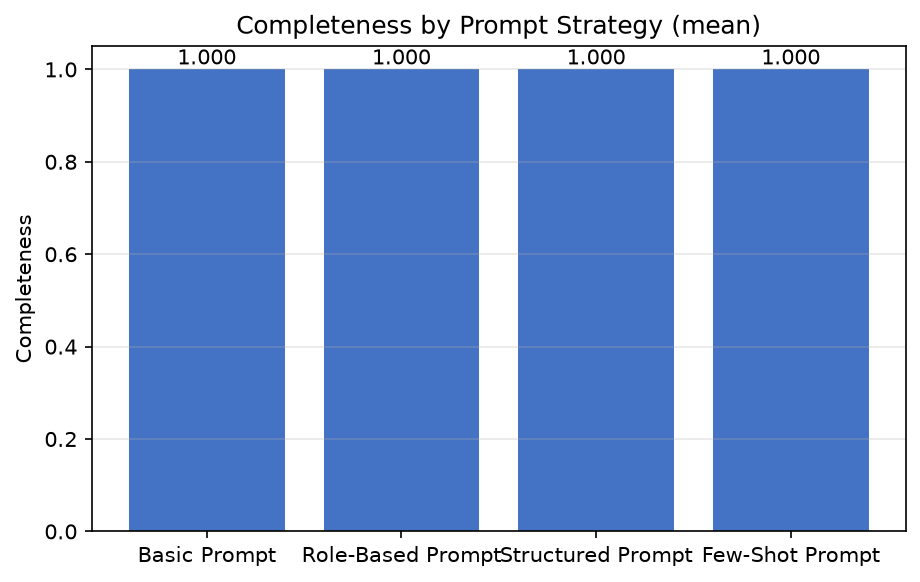

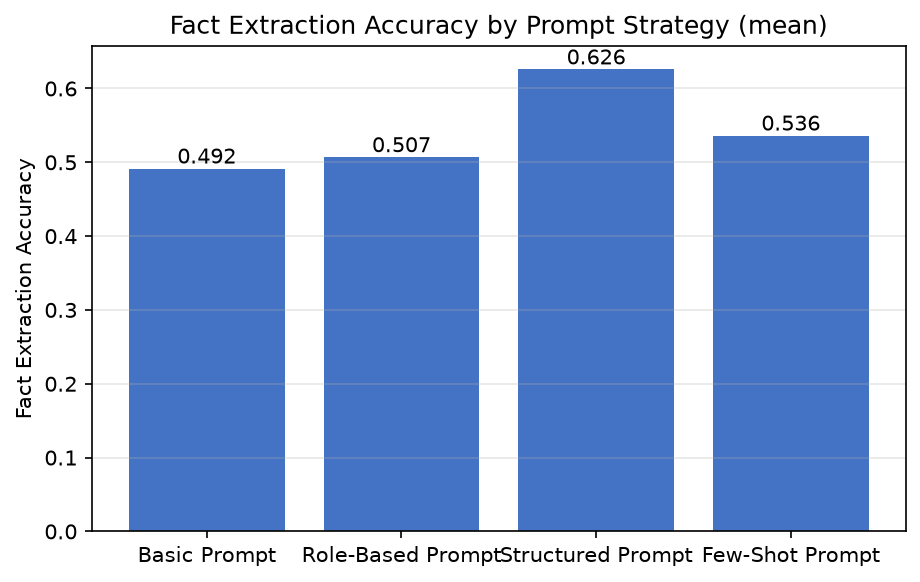

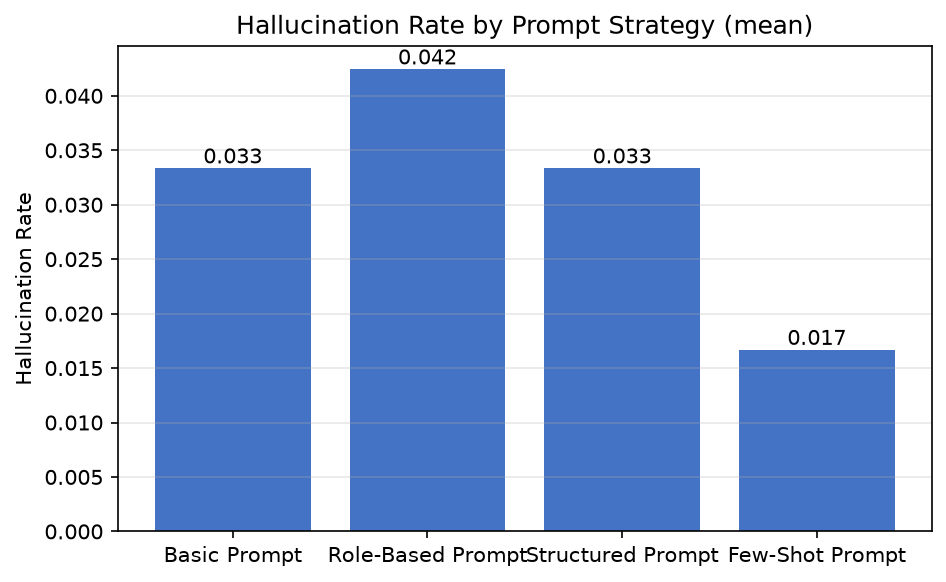

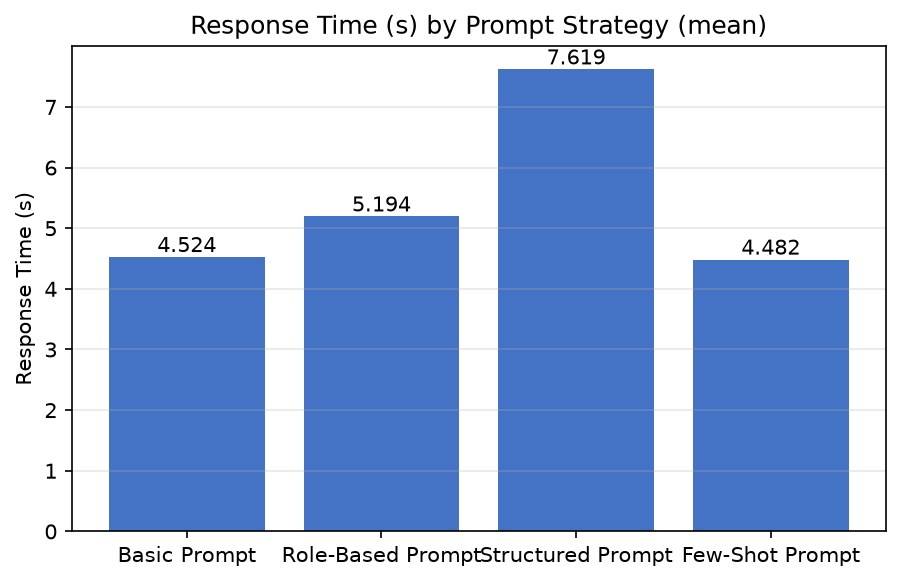

In [7]:
from IPython.display import Image, display
for png in sorted(settings.CHARTS_DIR.glob("bar_*.png")):
    display(Image(str(png)))

## 5. Qualitative error analysis

The plan requires documenting *why* errors occurred. The categories below
mirror the plan: incorrect/missed facts, missing sections, hallucinated
values, extraction failures.

In [8]:
# 5a. Hardest statements: lowest mean fact accuracy across strategies
hardest = (df.groupby(["statement_id", "doc_name"], observed=False)["fact_accuracy"]
             .mean().sort_values().head(5))
hardest

statement_id  doc_name                   
statement_20  ACTIVISIONBLIZZARD_2019_10K    0.000000
statement_18  VERIZON_2022_10K               0.000000
statement_16  PFIZER_2021_10K                0.083333
statement_17  Pfizer_2023Q2_10Q              0.083333
statement_19  3M_2018_10K                    0.125000
Name: fact_accuracy, dtype: float64

In [9]:
# 5b. Missed facts: which expected items did strategies fail to recover?
from src.engine.response_store import load_responses
from src.evaluation.evaluator import evaluate_record, load_ground_truth

latest = {}
for r in load_responses():
    if not r.get("error"):
        latest[(r["statement_id"], r["strategy"])] = r

missed_rows = []
for (sid, strategy), rec in sorted(latest.items()):
    gt = load_ground_truth(sid)
    ev = evaluate_record(rec, gt)
    id2q = {i["financebench_id"]: i for i in
            gt["expected_facts"] + gt["expected_ratios"]}
    for fid in ev["facts_missed"]:
        missed_rows.append({
            "statement_id": sid, "strategy": strategy,
            "question": id2q[fid]["question"][:110],
            "expected_answer": str(id2q[fid]["answer"])[:60],
        })
missed_df = pd.DataFrame(missed_rows)
print(f"{len(missed_df)} missed expected items across all experiments")
missed_df.groupby("strategy", observed=False).size()

130 missed expected items across all experiments


strategy
basic         36
few_shot      33
role_based    35
structured    26
dtype: int64

In [10]:
# Most frequently missed questions (candidates for 'why' discussion)
if len(missed_df):
    display(missed_df.groupby("question").size().sort_values(ascending=False)
            .head(10).to_frame("times_missed"))

,times_missed
question,
Are there any product categories / service categories that represent more than 20% of Boeing's revenue for FY2,4
"As of Q2'2023, is Pfizer spinning off any large business segments?",4
Assume that you are a public equities analyst. Answer the following question by primarily using information th,4
Did Pfizer grow its PPNE between FY20 and FY21?,4
Does AMD have a reasonably healthy liquidity profile based on its quick ratio for FY22? If the quick ratio is,4
Has Verizon increased its debt on balance sheet between 2022 and the 2021 fiscal period?,4
How much does Pfizer expect to pay to spin off Upjohn in the future in USD million?,4
Does Verizon have a reasonably healthy liquidity profile based on its quick ratio for FY 2022? If the quick ra,4
Which debt securities are registered to trade on a national securities exchange under American Express' name a,4


In [11]:
# 5c. Hallucinated values: ungrounded numeric claims per strategy
halluc_rows = []
for (sid, strategy), rec in sorted(latest.items()):
    ev = evaluate_record(rec, load_ground_truth(sid))
    for claim in ev["ungrounded_claims"]:
        halluc_rows.append({"statement_id": sid, "strategy": strategy, **claim})
halluc_df = pd.DataFrame(halluc_rows)
print(f"{len(halluc_df)} ungrounded numeric claims")
if len(halluc_df):
    display(halluc_df.groupby("strategy", observed=False).size().to_frame("claims"))
    display(halluc_df.head(10))

16 ungrounded numeric claims


,claims
strategy,
basic,4
few_shot,2
role_based,6
structured,4


,statement_id,strategy,field,value
0,statement_01,basic,Expenses,2.233700e+10
1,statement_01,basic,Expenses,2.233700e+04
2,statement_01,few_shot,Expenses,2.233700e+10
3,statement_01,few_shot,Expenses,2.233700e+04
4,statement_01,role_based,Expenses,2.233700e+10
5,statement_01,role_based,Expenses,2.233700e+04
6,statement_10,basic,Expenses,4.450300e+10
7,statement_10,basic,Expenses,4.450300e+04
8,statement_10,role_based,Expenses,4.450300e+10
9,statement_10,role_based,Expenses,4.450300e+04


In [12]:
# 5d. Missing sections: completeness gaps per strategy
gap_rows = []
for (sid, strategy), rec in sorted(latest.items()):
    ev = evaluate_record(rec, load_ground_truth(sid))
    for topic in ev["topics_missing"]:
        gap_rows.append({"statement_id": sid, "strategy": strategy, "topic": topic})
gaps = pd.DataFrame(gap_rows)
print(f"{len(gaps)} missing topic instances")
if len(gaps):
    display(gaps.pivot_table(index="strategy", columns="topic",
                             aggfunc="size", fill_value=0, observed=False))

0 missing topic instances


In [13]:
# 5e. Extraction failures / truncation exposure
proc_rows = []
for p in sorted(settings.PROCESSED_DIR.glob("*.json")):
    rec = json.loads(p.read_text(encoding="utf-8"))
    proc_rows.append({
        "doc_name": rec["doc_name"], "extractor": rec["extractor_used"],
        "fallback_reason": rec.get("fallback_reason"),
        "pages": rec["num_pages"], "chars": rec["char_count"],
        "truncated_in_prompt": rec["char_count"] > settings.MAX_INPUT_CHARS,
    })
pd.DataFrame(proc_rows)

,doc_name,extractor,fallback_reason,pages,chars,truncated_in_prompt
0,3M_2018_10K,pdfplumber,None,160,577446,True
1,3M_2022_10K,pdfplumber,None,252,922237,True
2,3M_2023Q2_10Q,pdfplumber,None,92,350609,True
3,ACTIVISIONBLIZZARD_2019_10K,pdfplumber,None,198,623482,True
4,AES_2022_10K,pdfplumber,None,257,901642,True
5,AMCOR_2023_10K,pdfplumber,None,156,483316,True
6,AMD_2022_10K,pdfplumber,None,121,410060,True
7,AMERICANEXPRESS_2022_10K,pdfplumber,None,260,815998,True
8,BESTBUY_2023_10K,pdfplumber,None,75,291516,True
9,BESTBUY_2024Q2_10Q,pdfplumber,None,30,94531,True


## 6. Findings

Run all cells above, then read the automatically computed findings:

- **Best strategy per metric** - see the summary table (section 3).
- **Why facts get missed** - the most-missed questions (5b) are typically
  multi-step calculations (e.g. year-over-year changes, ratios needing two
  statements) or facts located beyond the prompt-truncation window in very
  long 10-Ks (5e shows which documents were truncated).
- **Why hallucinations appear** - ungrounded claims (5c) concentrate where
  the statement text was truncated or where the model aggregated values
  (e.g. summing segments) instead of quoting reported figures.
- **Missing sections** (5d) concentrate in the `basic` strategy, which does
  not force a section checklist - a key argument for structured prompting.